 ## Assignment 2 

## Imports

In [ ]:

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score, confusion_matrix as sklearn_confusion_matrix,
    precision_recall_fscore_support, roc_auc_score
)
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor, LogisticRegression
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore", category=FutureWarning)
np.set_printoptions(precision=5, suppress=True)

RANDOM_GENERATOR = np.random.default_rng(42)
RANDOM_STATE = 42


## Part A 
task 1-4



In [5]:

def make_train_validation_test_split(features, targets, is_classification):
    """Return train, validation, and test splits using the assignment protocol."""
    if is_classification:
        stratify_for_test = targets
    else:
        stratify_for_test = None

    training_features, test_features, training_targets, test_targets = train_test_split(
        features,
        targets,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=stratify_for_test
    )

    if is_classification:
        stratify_for_validation = training_targets
    else:
        stratify_for_validation = None

    training_features, validation_features, training_targets, validation_targets = train_test_split(
        training_features,
        training_targets,
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=stratify_for_validation
    )

    return (
        training_features, validation_features, test_features,
        training_targets, validation_targets, test_targets
    )


def print_split_information(dataset_name, split_data, is_classification):
    """Print each split size and, for classification, its class counts."""
    training_features, validation_features, test_features = split_data[0:3]
    training_targets, validation_targets, test_targets = split_data[3:6]

    print(f"\n{dataset_name}")
    for split_name, split_features, split_targets in [
        ("Train", training_features, training_targets),
        ("Validation", validation_features, validation_targets),
        ("Test", test_features, test_targets)
    ]:
        print(f"{split_name:10s}: {len(split_features)} rows")
        if is_classification:
            class_values, class_counts = np.unique(split_targets, return_counts=True)
            print("             class counts:", dict(zip(class_values.tolist(), class_counts.tolist())))


# Diabetes: scaled=False is required so that Task 7 can compare raw and standardized features.
diabetes_data = load_diabetes(scaled=False)
diabetes_features = diabetes_data.data
diabetes_targets = diabetes_data.target

diabetes_splits = make_train_validation_test_split(
    diabetes_features, diabetes_targets, is_classification=False
)

# Breast cancer: make malignant = 1 positive and benign = 0.
breast_cancer_data = load_breast_cancer()
breast_cancer_features = breast_cancer_data.data
breast_cancer_targets = 1 - breast_cancer_data.target
breast_cancer_splits = make_train_validation_test_split(
    breast_cancer_features, breast_cancer_targets, is_classification=True
)

# Digits: labels are already integers 0 through 9.
digits_data = load_digits()
digits_features = digits_data.data / 16.0
digits_targets = digits_data.target
digits_splits = make_train_validation_test_split(
    digits_features, digits_targets, is_classification=True
)

# Iris: labels are already integers 0, 1, and 2.
iris_data = load_iris()
iris_features = iris_data.data
iris_targets = iris_data.target
iris_splits = make_train_validation_test_split(
    iris_features, iris_targets, is_classification=True
)

print_split_information("Diabetes", diabetes_splits, False)
print_split_information("Breast cancer", breast_cancer_splits, True)
print_split_information("Digits", digits_splits, True)
print_split_information("Iris", iris_splits, True)

expected_split_sizes = {
    "Diabetes": (264, 89, 89),
    "Breast cancer": (341, 114, 114),
    "Digits": (1077, 360, 360),
    "Iris": (90, 30, 30)
}
actual_split_sizes = {
    "Diabetes": tuple(len(part) for part in diabetes_splits[:3]),
    "Breast cancer": tuple(len(part) for part in breast_cancer_splits[:3]),
    "Digits": tuple(len(part) for part in digits_splits[:3]),
    "Iris": tuple(len(part) for part in iris_splits[:3])
}
assert actual_split_sizes == expected_split_sizes
print("\n All split sizes match the assignment table.")


Diabetes
Train     : 264 rows
Validation: 89 rows
Test      : 89 rows

Breast cancer
Train     : 341 rows
             class counts: {0: 214, 1: 127}
Validation: 114 rows
             class counts: {0: 71, 1: 43}
Test      : 114 rows
             class counts: {0: 72, 1: 42}

Digits
Train     : 1077 rows
             class counts: {0: 106, 1: 109, 2: 107, 3: 109, 4: 109, 5: 109, 6: 109, 7: 107, 8: 104, 9: 108}
Validation: 360 rows
             class counts: {0: 36, 1: 37, 2: 35, 3: 37, 4: 36, 5: 36, 6: 36, 7: 36, 8: 35, 9: 36}
Test      : 360 rows
             class counts: {0: 36, 1: 36, 2: 35, 3: 37, 4: 36, 5: 37, 6: 36, 7: 36, 8: 35, 9: 36}

Iris
Train     : 90 rows
             class counts: {0: 30, 1: 30, 2: 30}
Validation: 30 rows
             class counts: {0: 10, 1: 10, 2: 10}
Test      : 30 rows
             class counts: {0: 10, 1: 10, 2: 10}

 All split sizes match the assignment table.


In [7]:
#Task 2
class Standardizer:
    """Standardize columns using means and standard deviations from training data."""

    def fit(self, training_features):
        self.feature_means = np.mean(training_features, axis=0)
        self.feature_standard_deviations = np.std(training_features, axis=0)
        self.feature_standard_deviations[self.feature_standard_deviations == 0] = 1.0
        return self

    def transform(self, features):
        return (features - self.feature_means) / self.feature_standard_deviations

    def fit_transform(self, training_features):
        self.fit(training_features)
        return self.transform(training_features)


def add_bias_column(features):
    """Add a first column of ones so the intercept is part of the weight vector."""
    number_of_rows = features.shape[0]
    return np.column_stack((np.ones(number_of_rows), features))


def standardize_split(split_data):
    """Fit on training rows and apply the same transformation to all three splits."""
    training_features, validation_features, test_features = split_data[:3]
    standardizer = Standardizer()
    standardized_training_features = standardizer.fit_transform(training_features)
    standardized_validation_features = standardizer.transform(validation_features)
    standardized_test_features = standardizer.transform(test_features)
    return (
        standardized_training_features,
        standardized_validation_features,
        standardized_test_features,
        standardizer
    )

(
    diabetes_train, diabetes_validation, diabetes_test, diabetes_standardizer
) = standardize_split(diabetes_splits)
(
    cancer_train, cancer_validation, cancer_test, cancer_standardizer
) = standardize_split(breast_cancer_splits)

# Digits are divided by 16 as required and are not standardized.
digits_train, digits_validation, digits_test = digits_splits[:3]

(
    iris_train, iris_validation, iris_test, iris_standardizer
) = standardize_split(iris_splits)

print("Largest absolute standardized Diabetes training mean:",
      np.max(np.abs(np.mean(diabetes_train, axis=0))))
print("Smallest / largest Diabetes training standard deviation:",
      np.min(np.std(diabetes_train, axis=0)), np.max(np.std(diabetes_train, axis=0)))
assert np.max(np.abs(np.mean(diabetes_train, axis=0))) < 1e-9
assert np.max(np.abs(np.std(diabetes_train, axis=0) - 1.0)) < 1e-9

print("Validation feature means (not expected to be zero):", np.mean(diabetes_validation, axis=0))
print("Test feature means (not expected to be zero):", np.mean(diabetes_test, axis=0))


Largest absolute standardized Diabetes training mean: 2.2372676102294822e-15
Smallest / largest Diabetes training standard deviation: 0.9999999999999979 1.0000000000000004
Validation feature means (not expected to be zero): [ 0.02306 -0.14585  0.04301  0.19333  0.14308  0.04007  0.21744 -0.02896
  0.01042 -0.22111]
Test feature means (not expected to be zero): [-0.14885 -0.05594 -0.17199 -0.07271  0.093    0.09193  0.16346 -0.04716
 -0.12949 -0.25462]


Fit preprocessing statistics on training rows only so validation and test data do not influence the model
Using all rows leaks information about the held out data and makes the reported test performance misleading

In [9]:
#Task3

def mean_squared_error_from_scratch(true_values, predicted_values):
    differences = true_values - predicted_values
    return np.mean(differences ** 2)


def root_mean_squared_error(true_values, predicted_values):
    return np.sqrt(mean_squared_error_from_scratch(true_values, predicted_values))


def coefficient_of_determination(true_values, predicted_values):
    total_sum_of_squares = np.sum((true_values - np.mean(true_values)) ** 2)
    residual_sum_of_squares = np.sum((true_values - predicted_values) ** 2)
    return 1.0 - residual_sum_of_squares / total_sum_of_squares


def classification_accuracy(true_labels, predicted_labels):
    return np.mean(true_labels == predicted_labels)


def confusion_matrix_from_scratch(true_labels, predicted_labels, number_of_classes):
    """Rows are true classes and columns are predicted classes; uses vectorized counting."""
    result_matrix = np.zeros((number_of_classes, number_of_classes), dtype=int)
    np.add.at(result_matrix, (true_labels.astype(int), predicted_labels.astype(int)), 1)
    return result_matrix


def per_class_precision_recall_f1(confusion_matrix):
    true_positive_counts = np.diag(confusion_matrix).astype(float)
    predicted_positive_counts = np.sum(confusion_matrix, axis=0).astype(float)
    actual_positive_counts = np.sum(confusion_matrix, axis=1).astype(float)

    # Precision is defined as 0 for a class that is never predicted.
    class_precision = np.divide(
        true_positive_counts,
        predicted_positive_counts,
        out=np.zeros_like(true_positive_counts),
        where=predicted_positive_counts != 0
    )
    class_recall = np.divide(
        true_positive_counts,
        actual_positive_counts,
        out=np.zeros_like(true_positive_counts),
        where=actual_positive_counts != 0
    )
    class_f1 = np.divide(
        2 * class_precision * class_recall,
        class_precision + class_recall,
        out=np.zeros_like(class_precision),
        where=(class_precision + class_recall) != 0
    )

    return {
        "precision": class_precision,
        "recall": class_recall,
        "f1": class_f1,
        "macro_precision": np.mean(class_precision),
        "macro_recall": np.mean(class_recall),
        "macro_f1": np.mean(class_f1)
    }


# Compare the implemented metrics with scikit-learn on random labels.
metric_random_generator = np.random.default_rng(42)
random_true_classes = metric_random_generator.integers(0, 4, size=500)
random_predicted_classes = metric_random_generator.integers(0, 4, size=500)
random_regression_targets = metric_random_generator.normal(size=500)
random_regression_predictions = metric_random_generator.normal(size=500)

assert np.isclose(
    classification_accuracy(random_true_classes, random_predicted_classes),
    accuracy_score(random_true_classes, random_predicted_classes), atol=1e-12
)
assert np.array_equal(
    confusion_matrix_from_scratch(random_true_classes, random_predicted_classes, 4),
    sklearn_confusion_matrix(random_true_classes, random_predicted_classes, labels=[0, 1, 2, 3])
)
manual_class_metrics = per_class_precision_recall_f1(
    confusion_matrix_from_scratch(random_true_classes, random_predicted_classes, 4)
)
sklearn_precision, sklearn_recall, sklearn_f1, _ = precision_recall_fscore_support(
    random_true_classes, random_predicted_classes, labels=[0, 1, 2, 3], zero_division=0
)
assert np.allclose(manual_class_metrics["precision"], sklearn_precision, atol=1e-12)
assert np.allclose(manual_class_metrics["recall"], sklearn_recall, atol=1e-12)
assert np.allclose(manual_class_metrics["f1"], sklearn_f1, atol=1e-12)
assert np.isclose(
    mean_squared_error_from_scratch(random_regression_targets, random_regression_predictions),
    mean_squared_error(random_regression_targets, random_regression_predictions), atol=1e-12
)
assert np.isclose(
    root_mean_squared_error(random_regression_targets, random_regression_predictions),
    np.sqrt(mean_squared_error(random_regression_targets, random_regression_predictions)), atol=1e-12
)
assert np.isclose(
    coefficient_of_determination(random_regression_targets, random_regression_predictions),
    r2_score(random_regression_targets, random_regression_predictions), atol=1e-12
)
print("all requested metric checks passed")

all requested metric checks passed


In [10]:
#task4

def gradient_check(loss_function, gradient_function, weights, epsilon=1e-5,
                   number_of_entries=None, random_generator=None):
    """Compare an analytic gradient with central finite differences."""
    if random_generator is None:
        random_generator = np.random.default_rng(42)

    weights = np.asarray(weights, dtype=float)
    analytic_gradient = np.asarray(gradient_function(weights), dtype=float)
    numerical_gradient = np.zeros_like(weights, dtype=float)

    flat_weights = weights.reshape(-1)
    flat_numerical_gradient = numerical_gradient.reshape(-1)

    if number_of_entries is None or number_of_entries >= flat_weights.size:
        checked_flat_indices = np.arange(flat_weights.size)
    else:
        checked_flat_indices = random_generator.choice(
            flat_weights.size, size=number_of_entries, replace=False
        )

    for flat_index in checked_flat_indices:
        positive_weights = flat_weights.copy()
        negative_weights = flat_weights.copy()
        positive_weights[flat_index] += epsilon
        negative_weights[flat_index] -= epsilon

        positive_loss = loss_function(positive_weights.reshape(weights.shape))
        negative_loss = loss_function(negative_weights.reshape(weights.shape))
        flat_numerical_gradient[flat_index] = (positive_loss - negative_loss) / (2 * epsilon)

    flat_analytic_gradient = analytic_gradient.reshape(-1)
    selected_analytic_gradient = flat_analytic_gradient[checked_flat_indices]
    selected_numerical_gradient = flat_numerical_gradient[checked_flat_indices]

    numerator = np.linalg.norm(selected_analytic_gradient - selected_numerical_gradient)
    denominator = max(
        np.linalg.norm(selected_analytic_gradient),
        np.linalg.norm(selected_numerical_gradient),
        1e-12
    )
    return numerator / denominator

print("Gradient checker is ready")

Gradient checker is ready


## Part B  Linear regression 

In [11]:

def linear_regression_loss(weights, features_with_bias, true_values):
    number_of_samples = len(true_values)
    prediction_errors = features_with_bias @ weights - true_values
    return np.sum(prediction_errors ** 2) / (2 * number_of_samples)


def linear_regression_gradient(weights, features_with_bias, true_values):
    number_of_samples = len(true_values)
    prediction_errors = features_with_bias @ weights - true_values
    return features_with_bias.T @ prediction_errors / number_of_samples


def normal_equation(features, true_values):
    features_with_bias = add_bias_column(features)
    left_side = features_with_bias.T @ features_with_bias
    right_side = features_with_bias.T @ true_values
    # Use solve(), as required; do not calculate an explicit matrix inverse.
    return np.linalg.solve(left_side, right_side)


def ridge_closed_form(features, true_values, regularization_strength):
    features_with_bias = add_bias_column(features)
    number_of_samples = len(true_values)
    number_of_parameters = features_with_bias.shape[1]
    regularization_matrix = np.eye(number_of_parameters)
    regularization_matrix[0, 0] = 0.0  # Do not penalize the bias.

    left_side = features_with_bias.T @ features_with_bias / number_of_samples
    left_side += regularization_strength * regularization_matrix
    right_side = features_with_bias.T @ true_values / number_of_samples
    return np.linalg.solve(left_side, right_side)


def train_batch_linear_regression(features, true_values, learning_rate, number_of_epochs,
                                  regularization_strength=0.0, initial_weights=None):
    features_with_bias = add_bias_column(features)
    number_of_samples, number_of_parameters = features_with_bias.shape
    if initial_weights is None:
        weights = np.zeros(number_of_parameters)
    else:
        weights = initial_weights.astype(float).copy()

    regularization_mask = np.ones(number_of_parameters)
    regularization_mask[0] = 0.0
    loss_history = []
    weight_history = []

    for epoch_number in range(number_of_epochs):
        prediction_errors = features_with_bias @ weights - true_values
        gradient = features_with_bias.T @ prediction_errors / number_of_samples
        gradient += regularization_strength * regularization_mask * weights
        weights -= learning_rate * gradient

        data_loss = linear_regression_loss(weights, features_with_bias, true_values)
        loss_history.append(data_loss)
        weight_history.append(weights.copy())
        if not np.all(np.isfinite(weights)) or not np.isfinite(data_loss):
            break

    return weights, np.asarray(loss_history), np.asarray(weight_history)


def linear_relative_distance(current_weights, optimal_weights):
    return np.linalg.norm(current_weights - optimal_weights) / max(np.linalg.norm(optimal_weights), 1e-12)


def evaluate_regression_weights(weights, training_features, validation_features, test_features,
                                training_targets, validation_targets, test_targets):
    training_predictions = add_bias_column(training_features) @ weights
    validation_predictions = add_bias_column(validation_features) @ weights
    test_predictions = add_bias_column(test_features) @ weights
    return {
        "train_rmse": root_mean_squared_error(training_targets, training_predictions),
        "validation_rmse": root_mean_squared_error(validation_targets, validation_predictions),
        "test_rmse": root_mean_squared_error(test_targets, test_predictions),
        "test_r2": coefficient_of_determination(test_targets, test_predictions)
    }


In [13]:
#task5

diabetes_training_targets = diabetes_splits[3]
diabetes_validation_targets = diabetes_splits[4]
diabetes_test_targets = diabetes_splits[5]

closed_form_weights = normal_equation(diabetes_train, diabetes_training_targets)
closed_form_metrics = evaluate_regression_weights(
    closed_form_weights,
    diabetes_train, diabetes_validation, diabetes_test,
    diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
)
condition_number_standardized = np.linalg.cond(add_bias_column(diabetes_train).T @ add_bias_column(diabetes_train))

linear_regression_library = LinearRegression()
linear_regression_library.fit(diabetes_train, diabetes_training_targets)
library_closed_form_weights = np.concatenate((
    [linear_regression_library.intercept_], linear_regression_library.coef_
))
weight_difference = np.max(np.abs(closed_form_weights - library_closed_form_weights))

feature_weight_table = pd.DataFrame({
    "Feature": ["bias"] + list(diabetes_data.feature_names),
    "Weight": closed_form_weights,
    "Train RMSE": closed_form_metrics["train_rmse"],
    "Validation RMSE": closed_form_metrics["validation_rmse"],
    "Test RMSE": closed_form_metrics["test_rmse"],
    "Test R2": closed_form_metrics["test_r2"],
    "Condition number": condition_number_standardized
})
print(feature_weight_table.to_string(index=False))
print("\nRegression metrics:", closed_form_metrics)
print("Condition number:", condition_number_standardized)
print("Maximum difference from LinearRegression weights:", weight_difference)
assert weight_difference < 1e-6


Feature     Weight  Train RMSE  Validation RMSE  Test RMSE  Test R2  Condition number
   bias 149.810606   54.610364        51.193714  54.156413 0.446426        505.706123
    age   1.131837   54.610364        51.193714  54.156413 0.446426        505.706123
    sex -11.359311   54.610364        51.193714  54.156413 0.446426        505.706123
    bmi  25.076618   54.610364        51.193714  54.156413 0.446426        505.706123
     bp  15.167338   54.610364        51.193714  54.156413 0.446426        505.706123
     s1 -51.101359   54.610364        51.193714  54.156413 0.446426        505.706123
     s2  27.480823   54.610364        51.193714  54.156413 0.446426        505.706123
     s3  10.840294   54.610364        51.193714  54.156413 0.446426        505.706123
     s4  15.032148   54.610364        51.193714  54.156413 0.446426        505.706123
     s5  37.271588   54.610364        51.193714  54.156413 0.446426        505.706123
     s6   3.817112   54.610364        51.193714  54.15

While bmi and s2 have large positive weights (indicating higher values increase predicted disease progression), s1 has a large negative weight of comparable magnitude, even though total cholesterol (s1) and LDL (s2) are both biologically associated with higher diabetes risk. Because s1 and s2 are strongly positively correlated (multicollinear), the linear model assigns them large opposing weights that partially cancel each other out to fit subtle noise in the training set rather than reflecting their independent effects. Consequently, interpreting individual weights in isolation is risky because correlated features cause high variance in coefficient estimates—small changes in the training data can dramatically flip their signs or magnitudes without affecting the model's overall predictions.

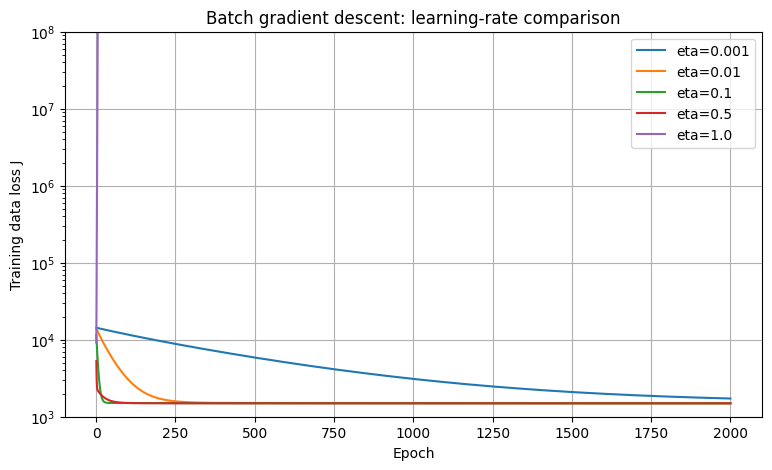

,learning_rate,final_loss,final_relative_distance,first_epoch_below_1e-3,diverged
0,0.001,1723.402889,4.051131e-01,not reached,False
1,0.010,1503.686676,3.345214e-01,not reached,False
2,0.100,1491.892636,8.179229e-02,not reached,False
3,0.500,1491.145907,1.546262e-04,1524,False
4,1.000,inf,4.002419e+150,not reached,True


Largest eigenvalue: 3.9547550320503744
Theoretical learning-rate threshold 2 / largest_eigenvalue: 0.5057203249737277


,run,learning_rate,final_loss,diverged
0,below_threshold,0.480434,1.492930e+03,False
1,above_threshold,0.531006,5.971177e+27,True


In [17]:
# task6
learning_rates_to_test = [0.001, 0.01, 0.1, 0.5, 1.0]
number_of_gradient_descent_epochs = 2000

linear_gradient_descent_results = {}
linear_gradient_descent_rows = []

with np.errstate(over="ignore", invalid="ignore"):
    for learning_rate in learning_rates_to_test:
        final_weights, loss_history, weight_history = train_batch_linear_regression(
            diabetes_train, diabetes_training_targets,
            learning_rate, number_of_gradient_descent_epochs
        )
        distance_history = np.array([
            linear_relative_distance(epoch_weights, closed_form_weights)
            for epoch_weights in weight_history
        ])
        reached_indices = np.where(distance_history < 1e-3)[0]
        first_epoch_reached = int(reached_indices[0] + 1) if len(reached_indices) else "not reached"

        linear_gradient_descent_results[learning_rate] = {
            "weights": final_weights,
            "loss_history": loss_history,
            "distance_history": distance_history
        }
        linear_gradient_descent_rows.append({
            "learning_rate": learning_rate,
            "final_loss": loss_history[-1] if len(loss_history) else np.nan,
            "final_relative_distance": distance_history[-1] if len(distance_history) else np.nan,
            "first_epoch_below_1e-3": first_epoch_reached,
            "diverged": (
                not np.all(np.isfinite(final_weights))
                or not np.isfinite(loss_history[-1])
                or loss_history[-1] > 1e20
            )
        })

plt.figure(figsize=(9, 5))
for learning_rate, result in linear_gradient_descent_results.items():
    losses = np.asarray(result["loss_history"], dtype=float)
    safe_losses = np.where(
        np.isfinite(losses) & (losses < 1e10),
        np.maximum(losses, 1e-15),
        np.nan
    )
    plt.plot(np.arange(1, len(safe_losses) + 1), safe_losses, label=f"eta={learning_rate}")

plt.yscale("log")
plt.ylim(1e3, 1e8)
plt.xlabel("Epoch")
plt.ylabel("Training data loss J")
plt.title("Batch gradient descent: learning-rate comparison")
plt.legend()
plt.grid(True)
plt.show()

linear_gradient_descent_table = pd.DataFrame(linear_gradient_descent_rows)
display(linear_gradient_descent_table)

features_with_bias = add_bias_column(diabetes_train)
hessian_matrix = features_with_bias.T @ features_with_bias / len(diabetes_training_targets)
largest_eigenvalue = np.max(np.linalg.eigvalsh(hessian_matrix))
learning_rate_limit = 2.0 / largest_eigenvalue
print("Largest eigenvalue:", largest_eigenvalue)
print("Theoretical learning-rate threshold 2 / largest_eigenvalue:", learning_rate_limit)

threshold_learning_rates = {
    "below_threshold": 0.95 * learning_rate_limit,
    "above_threshold": 1.05 * learning_rate_limit
}
threshold_rows = []
with np.errstate(over="ignore", invalid="ignore"):
    for schedule_name, learning_rate in threshold_learning_rates.items():
        threshold_weights, threshold_losses, _ = train_batch_linear_regression(
            diabetes_train, diabetes_training_targets, learning_rate, 300
        )
        threshold_rows.append({
            "run": schedule_name,
            "learning_rate": learning_rate,
            "final_loss": threshold_losses[-1] if len(threshold_losses) else np.nan,
            "diverged": (
                not np.all(np.isfinite(threshold_weights))
                or not np.isfinite(threshold_losses[-1])
                or threshold_losses[-1] > 1e20
            )
        })
display(pd.DataFrame(threshold_rows))



Derivation note: 
along an eigenvector with eigenvalue q, the error is multiplied by (1 - eta*q)
Convergence requires |1 - eta*q| < 1 for every eigenvalue; the strict upper bound is eta < 2 / lambda_max.

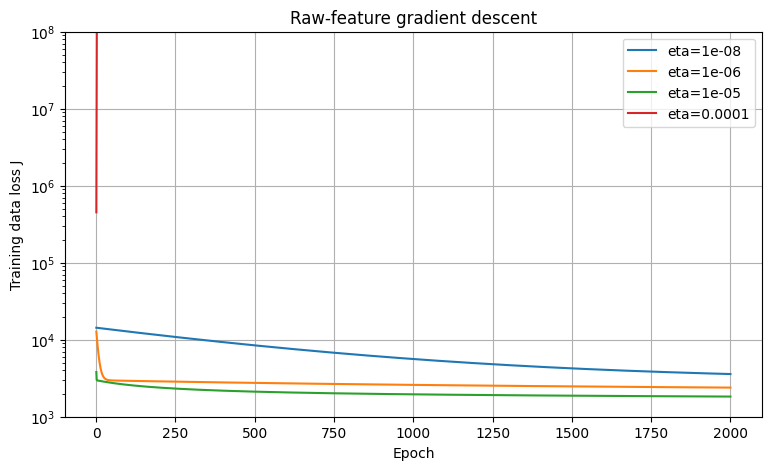

,learning_rate,final_loss,relative_distance,diverged
0,1.000000e-08,3583.532102,9.999986e-01,False
1,1.000000e-06,2388.752582,9.999676e-01,False
2,1.000000e-05,1827.534910,9.998464e-01,False
3,1.000000e-04,inf,1.366696e+148,True


Standardized condition number: 505.70612269609995
Raw-feature condition number: 55778473.21852342
Standardized 2/lambda_max: 0.5057203249737277
Raw-feature 2/lambda_max: 2.7427928748390996e-05


In [20]:
# task7
raw_diabetes_train = diabetes_splits[0]
raw_diabetes_validation = diabetes_splits[1]
raw_diabetes_test = diabetes_splits[2]
raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]
raw_optimal_weights = normal_equation(raw_diabetes_train, diabetes_training_targets)
raw_features_with_bias = add_bias_column(raw_diabetes_train)
raw_hessian = raw_features_with_bias.T @ raw_features_with_bias / len(diabetes_training_targets)
raw_largest_eigenvalue = np.max(np.linalg.eigvalsh(raw_hessian))
raw_learning_rate_limit = 2.0 / raw_largest_eigenvalue
raw_condition_number = np.linalg.cond(raw_features_with_bias.T @ raw_features_with_bias)

raw_gradient_descent_rows = []
raw_gradient_descent_results = {}

# Changed: wrapped the training loop in np.errstate to suppress expected float64 overflow
# warnings when eta=1e-4 (which exceeds 2/lambda_max) diverges to infinity.
with np.errstate(over="ignore", invalid="ignore"):
    for learning_rate in raw_learning_rates:
        raw_weights, raw_losses, raw_weight_history = train_batch_linear_regression(
            raw_diabetes_train, diabetes_training_targets, learning_rate, 2000
        )
        raw_gradient_descent_results[learning_rate] = raw_losses
        raw_gradient_descent_rows.append({
            "learning_rate": learning_rate,
            "final_loss": raw_losses[-1] if len(raw_losses) else np.nan,
            "relative_distance": linear_relative_distance(raw_weights, raw_optimal_weights),
            "diverged": (
                not np.all(np.isfinite(raw_weights))
                or not np.isfinite(raw_losses[-1])
                or raw_losses[-1] > 1e20
            )
        })

plt.figure(figsize=(9, 5))
for learning_rate, loss_history in raw_gradient_descent_results.items():
    # Changed: replaced raw np.maximum(loss_history, 1e-15) with np.where masking inf/nan
    # and values > 1e10 as np.nan. Passing huge exploded floats (~1e300) or inf from eta=1e-4
    # to a log-scale plot overflows Matplotlib's axis tick locator and leaves the plot blank.
    losses = np.asarray(loss_history, dtype=float)
    safe_losses = np.where(
        np.isfinite(losses) & (losses < 1e10),
        np.maximum(losses, 1e-15),
        np.nan
    )
    plt.plot(np.arange(1, len(safe_losses) + 1), safe_losses,
             label=f"eta={learning_rate:g}")

plt.yscale("log")
# Changed: added fixed y-limits so the converging curves remain clearly visible and
# aren't compressed or broken by the diverging eta=1e-4 trajectory shooting off the top.
plt.ylim(1e3, 1e8)
plt.xlabel("Epoch")
plt.ylabel("Training data loss J")
plt.title("Raw-feature gradient descent")
plt.legend()
plt.grid(True)
plt.show()

display(pd.DataFrame(raw_gradient_descent_rows))
print("Standardized condition number:", condition_number_standardized)
print("Raw-feature condition number:", raw_condition_number)
print("Standardized 2/lambda_max:", learning_rate_limit)
print("Raw-feature 2/lambda_max:", raw_learning_rate_limit)


Without feature scaling, variables with large numeric ranges inflate the largest eigenvalue $\lambda_{\max}$


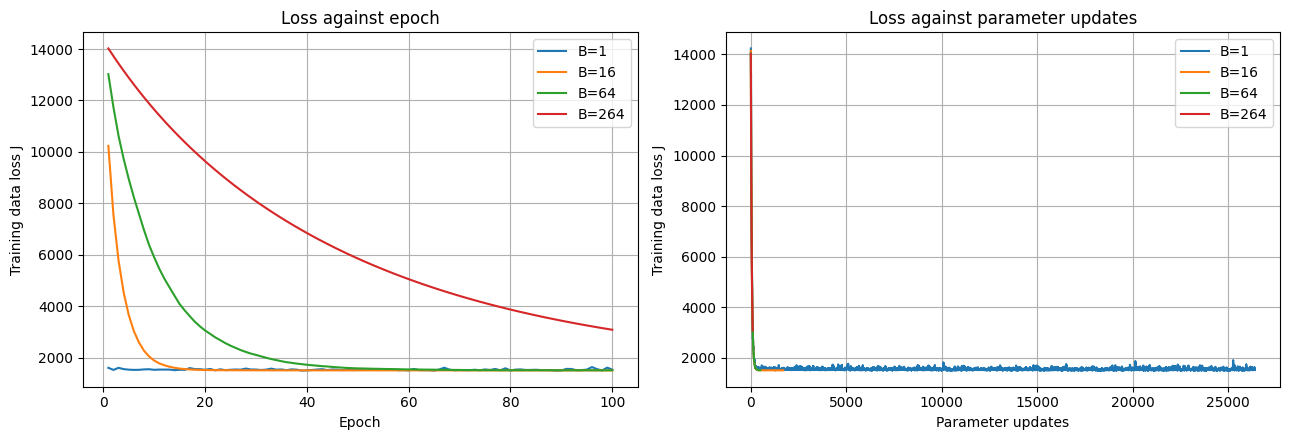

,batch_size,updates,final_training_loss
0,1,26400,1534.808385
1,16,1700,1505.665099
2,64,500,1511.375336
3,264,100,3085.440479


,batch_size,learning_rate,final_loss
0,1,0.001,1503.312177
1,1,0.010,1534.808385
2,1,0.100,4186.980952


In [22]:
#task8
def train_linear_mini_batch(features, true_values, learning_rate, number_of_epochs, batch_size,
                            random_generator=None, record_each_update=False):
    """Train linear regression with shuffled mini-batches; the last partial batch is kept."""
    if random_generator is None:
        random_generator = np.random.default_rng(42)

    features_with_bias = add_bias_column(features)
    number_of_samples = len(true_values)
    weights = np.zeros(features_with_bias.shape[1])
    epoch_loss_history = []
    update_loss_history = []
    number_of_updates = 0

    for epoch_number in range(number_of_epochs):
        shuffled_indices = random_generator.permutation(number_of_samples)
        for first_index in range(0, number_of_samples, batch_size):
            last_index = min(first_index + batch_size, number_of_samples)
            batch_indices = shuffled_indices[first_index:last_index]
            batch_features = features_with_bias[batch_indices]
            batch_targets = true_values[batch_indices]
            batch_errors = batch_features @ weights - batch_targets
            batch_gradient = batch_features.T @ batch_errors / len(batch_targets)
            weights -= learning_rate * batch_gradient
            number_of_updates += 1

            if record_each_update:
                update_loss_history.append(
                    linear_regression_loss(weights, features_with_bias, true_values)
                )

        epoch_loss_history.append(
            linear_regression_loss(weights, features_with_bias, true_values)
        )

    return weights, np.asarray(epoch_loss_history), np.asarray(update_loss_history), number_of_updates

batch_sizes_to_test = [1, 16, 64, len(diabetes_training_targets)]
mini_batch_results = {}
mini_batch_rows = []
for batch_size in batch_sizes_to_test:
    batch_weights, epoch_losses, update_losses, update_count = train_linear_mini_batch(
        diabetes_train,
        diabetes_training_targets,
        learning_rate=0.01,
        number_of_epochs=100,
        batch_size=batch_size,
        random_generator=np.random.default_rng(42),
        record_each_update=True
    )
    mini_batch_results[batch_size] = {
        "weights": batch_weights,
        "epoch_losses": epoch_losses,
        "update_losses": update_losses,
        "update_count": update_count
    }
    mini_batch_rows.append({
        "batch_size": batch_size,
        "updates": update_count,
        "final_training_loss": epoch_losses[-1]
    })

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for batch_size, result in mini_batch_results.items():
    axes[0].plot(np.arange(1, len(result["epoch_losses"]) + 1),
                 result["epoch_losses"], label=f"B={batch_size}")
    axes[1].plot(np.arange(1, len(result["update_losses"]) + 1),
                 result["update_losses"], label=f"B={batch_size}")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training data loss J")
axes[0].set_title("Loss against epoch")
axes[0].legend()
axes[1].set_xlabel("Parameter updates")
axes[1].set_ylabel("Training data loss J")
axes[1].set_title("Loss against parameter updates")
axes[1].legend()
for axis in axes:
    axis.grid(True)
plt.tight_layout()
plt.show()
display(pd.DataFrame(mini_batch_rows))

single_sample_rows = []
for learning_rate in [0.001, 0.01, 0.1]:
    _, single_sample_losses, _, _ = train_linear_mini_batch(
        diabetes_train, diabetes_training_targets, learning_rate, 100, 1,
        random_generator=np.random.default_rng(42)
    )
    single_sample_rows.append({
        "batch_size": 1,
        "learning_rate": learning_rate,
        "final_loss": single_sample_losses[-1]
    })
display(pd.DataFrame(single_sample_rows))


Smaller batches  make faster progress per epoch because they update the weights many more times per pass

Original 10-feature ridge results:


,lambda,validation_rmse,test_rmse
0,0.000000,51.193714,54.156413
1,0.001000,51.149556,54.108184
2,0.003162,51.108041,54.043664
3,0.010000,51.104749,53.958452
4,0.031623,51.153130,53.860008
5,0.100000,51.207305,53.708925
6,0.316228,51.577988,53.672447
7,1.000000,53.695124,54.856860
8,3.162278,59.420332,59.092797
9,10.000000,66.954649,65.303877


Best validation lambda: 0.01

Degree-2 ridge results:


,lambda,validation_rmse,test_rmse
0,0.000000,59.205949,62.133373
1,0.001000,54.207871,53.651494
2,0.003162,53.053194,52.619781
3,0.010000,52.106089,52.618039
4,0.031623,51.474170,53.119921
5,0.100000,51.270640,53.615580
6,0.316228,51.316252,53.872938
7,1.000000,51.497243,53.996459
8,3.162278,52.630193,54.601831
9,10.000000,56.640332,57.237038


Best degree-2 lambda: 0.1


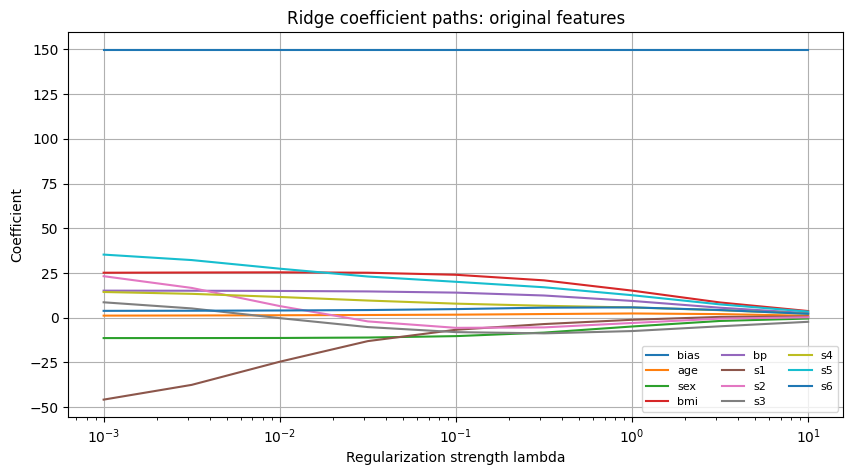

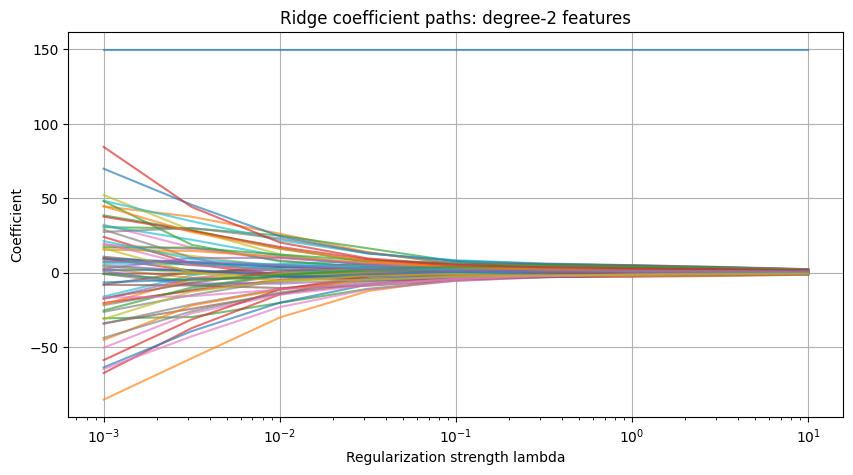

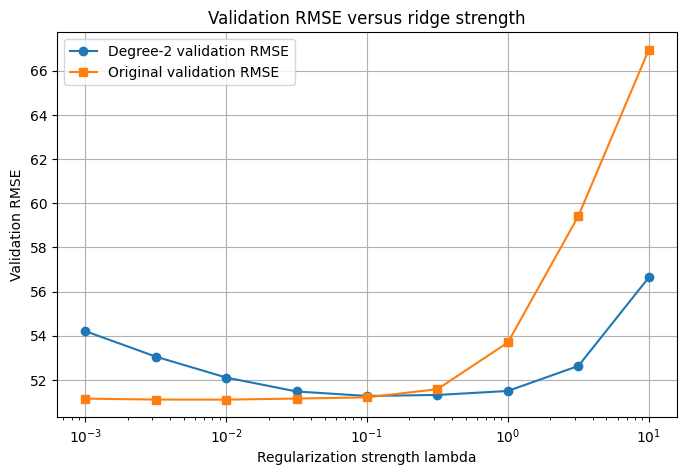

Original features: lambda=0 test RMSE = 54.15641293326045
Original features: best-lambda test RMSE = 53.9584521494208
Degree-2 features: lambda=0 test RMSE = 62.13337339481438
Degree-2 features: best-lambda test RMSE = 53.61558011674492
Degree-2 condition number: 1289356227.322789
Relative distance: ridge GD vs closed form: 7.740937282134551e-16
Maximum difference: ridge closed form vs sklearn Ridge: 1.3500311979441904e-13


In [24]:
#task9
def make_degree_two_features(features, feature_names):
    """Include original features and pairwise products x_a*x_b for a <= b.

    The sex-squared column is excluded because sex is coded 1/2 and its square
    is exactly a linear combination of sex and the bias.
    """
    expanded_columns = [features]
    expanded_feature_names = list(feature_names)

    for first_feature_index in range(features.shape[1]):
        for second_feature_index in range(first_feature_index, features.shape[1]):
            first_name = feature_names[first_feature_index]
            second_name = feature_names[second_feature_index]
            if first_name == "sex" and second_name == "sex":
                continue
            product_column = (
                features[:, first_feature_index] * features[:, second_feature_index]
            ).reshape(-1, 1)
            expanded_columns.append(product_column)
            expanded_feature_names.append(f"{first_name}*{second_name}")

    return np.column_stack(expanded_columns), expanded_feature_names


regularization_values = np.concatenate(([0.0], np.logspace(-3, 1, 9)))

# (i) The original 10 standardized features.
original_feature_ridge_results = []
original_feature_ridge_weights = {}
for regularization_strength in regularization_values:
    ridge_weights = ridge_closed_form(
        diabetes_train, diabetes_training_targets, regularization_strength
    )
    ridge_metrics = evaluate_regression_weights(
        ridge_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )
    original_feature_ridge_weights[regularization_strength] = ridge_weights
    original_feature_ridge_results.append({
        "lambda": regularization_strength,
        "validation_rmse": ridge_metrics["validation_rmse"],
        "test_rmse": ridge_metrics["test_rmse"]
    })

original_feature_ridge_table = pd.DataFrame(original_feature_ridge_results)
best_original_feature_row = original_feature_ridge_table.loc[
    original_feature_ridge_table["validation_rmse"].idxmin()
]
print("Original 10-feature ridge results:")
display(original_feature_ridge_table)
print("Best validation lambda:", best_original_feature_row["lambda"])

# (ii) Build the 64-feature degree-2 expansion, then standardize it with training statistics.
all_diabetes_features = diabetes_features
all_expanded_features, expanded_feature_names = make_degree_two_features(
    all_diabetes_features, list(diabetes_data.feature_names)
)
expanded_splits = make_train_validation_test_split(
    all_expanded_features, diabetes_targets, is_classification=False
)
expanded_training_raw, expanded_validation_raw, expanded_test_raw = expanded_splits[:3]
expanded_training_targets, expanded_validation_targets, expanded_test_targets = expanded_splits[3:6]
expanded_standardizer = Standardizer()
expanded_train = expanded_standardizer.fit_transform(expanded_training_raw)
expanded_validation = expanded_standardizer.transform(expanded_validation_raw)
expanded_test = expanded_standardizer.transform(expanded_test_raw)
assert expanded_train.shape[1] == 64

expanded_ridge_results = []
expanded_ridge_weights = {}
for regularization_strength in regularization_values:
    ridge_weights = ridge_closed_form(
        expanded_train, expanded_training_targets, regularization_strength
    )
    ridge_metrics = evaluate_regression_weights(
        ridge_weights, expanded_train, expanded_validation, expanded_test,
        expanded_training_targets, expanded_validation_targets, expanded_test_targets
    )
    expanded_ridge_weights[regularization_strength] = ridge_weights
    expanded_ridge_results.append({
        "lambda": regularization_strength,
        "validation_rmse": ridge_metrics["validation_rmse"],
        "test_rmse": ridge_metrics["test_rmse"]
    })

expanded_ridge_table = pd.DataFrame(expanded_ridge_results)
best_expanded_feature_row = expanded_ridge_table.loc[
    expanded_ridge_table["validation_rmse"].idxmin()
]
print("\nDegree-2 ridge results:")
display(expanded_ridge_table)
print("Best degree-2 lambda:", best_expanded_feature_row["lambda"])

# Coefficient paths for positive lambda values (lambda=0 cannot be placed on a log x-axis).
positive_regularization_values = regularization_values[regularization_values > 0]
plt.figure(figsize=(10, 5))
for feature_index, feature_name in enumerate(["bias"] + list(diabetes_data.feature_names)):
    coefficient_values = [original_feature_ridge_weights[value][feature_index]
                          for value in positive_regularization_values]
    plt.plot(positive_regularization_values, coefficient_values, label=feature_name)
plt.xscale("log")
plt.xlabel("Regularization strength lambda")
plt.ylabel("Coefficient")
plt.title("Ridge coefficient paths: original features")
plt.legend(ncol=3, fontsize=8)
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
for feature_index in range(expanded_train.shape[1] + 1):
    coefficient_values = [expanded_ridge_weights[value][feature_index]
                          for value in positive_regularization_values]
    plt.plot(positive_regularization_values, coefficient_values, alpha=0.65)
plt.xscale("log")
plt.xlabel("Regularization strength lambda")
plt.ylabel("Coefficient")
plt.title("Ridge coefficient paths: degree-2 features")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(positive_regularization_values,
         [expanded_ridge_table.loc[expanded_ridge_table["lambda"] == value, "validation_rmse"].iloc[0]
          for value in positive_regularization_values], marker="o", label="Degree-2 validation RMSE")
plt.plot(positive_regularization_values,
         [original_feature_ridge_table.loc[original_feature_ridge_table["lambda"] == value, "validation_rmse"].iloc[0]
          for value in positive_regularization_values], marker="s", label="Original validation RMSE")
plt.xscale("log")
plt.xlabel("Regularization strength lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE versus ridge strength")
plt.legend()
plt.grid(True)
plt.show()

print("Original features: lambda=0 test RMSE =",
      original_feature_ridge_table.loc[original_feature_ridge_table["lambda"] == 0, "test_rmse"].iloc[0])
print("Original features: best-lambda test RMSE =", best_original_feature_row["test_rmse"])
print("Degree-2 features: lambda=0 test RMSE =",
      expanded_ridge_table.loc[expanded_ridge_table["lambda"] == 0, "test_rmse"].iloc[0])
print("Degree-2 features: best-lambda test RMSE =", best_expanded_feature_row["test_rmse"])
print("Degree-2 condition number:", np.linalg.cond(add_bias_column(expanded_train).T @ add_bias_column(expanded_train)))

# Verify ridge against gradient descent and scikit-learn on the original 10 features.
ridge_check_lambda = 0.1
ridge_check_closed_form = ridge_closed_form(
    diabetes_train, diabetes_training_targets, ridge_check_lambda
)
ridge_check_gd_weights, _, _ = train_batch_linear_regression(
    diabetes_train, diabetes_training_targets,
    learning_rate=0.4, number_of_epochs=3000,
    regularization_strength=ridge_check_lambda
)
ridge_check_library = Ridge(alpha=ridge_check_lambda * len(diabetes_training_targets))
ridge_check_library.fit(diabetes_train, diabetes_training_targets)
ridge_check_library_weights = np.concatenate((
    [ridge_check_library.intercept_], ridge_check_library.coef_
))
print("Relative distance: ridge GD vs closed form:",
      linear_relative_distance(ridge_check_gd_weights, ridge_check_closed_form))
print("Maximum difference: ridge closed form vs sklearn Ridge:",
      np.max(np.abs(ridge_check_closed_form - ridge_check_library_weights)))


Ridge tames overfitting when features (64) near sample size (264), while unpenalized bias keeps predictions centered at zero-feature baseline.

In [26]:
#task 10
comparison_rows = []
optimal_unregularized_weights = normal_equation(diabetes_train, diabetes_training_targets)

# Exact normal equation.
start_time = time.perf_counter()
comparison_normal_weights = normal_equation(diabetes_train, diabetes_training_targets)
normal_fit_time = time.perf_counter() - start_time
comparison_rows.append({
    "method": "Normal equation (scratch)",
    "test_RMSE": evaluate_regression_weights(
        comparison_normal_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )["test_rmse"],
    "relative_weight_distance": linear_relative_distance(comparison_normal_weights, optimal_unregularized_weights),
    "fit_time_seconds": normal_fit_time
})

# Batch gradient descent.
start_time = time.perf_counter()
comparison_batch_weights, _, _ = train_batch_linear_regression(
    diabetes_train, diabetes_training_targets, learning_rate=0.5, number_of_epochs=2000
)
batch_fit_time = time.perf_counter() - start_time
comparison_rows.append({
    "method": "Batch GD (scratch)",
    "test_RMSE": evaluate_regression_weights(
        comparison_batch_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )["test_rmse"],
    "relative_weight_distance": linear_relative_distance(comparison_batch_weights, optimal_unregularized_weights),
    "fit_time_seconds": batch_fit_time
})

# Mini-batch gradient descent.
start_time = time.perf_counter()
comparison_mini_weights, _, _, _ = train_linear_mini_batch(
    diabetes_train, diabetes_training_targets, learning_rate=0.01,
    number_of_epochs=100, batch_size=16, random_generator=np.random.default_rng(42)
)
mini_fit_time = time.perf_counter() - start_time
comparison_rows.append({
    "method": "Mini-batch GD B=16 (scratch)",
    "test_RMSE": evaluate_regression_weights(
        comparison_mini_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )["test_rmse"],
    "relative_weight_distance": linear_relative_distance(comparison_mini_weights, optimal_unregularized_weights),
    "fit_time_seconds": mini_fit_time
})

# Ridge regression with lambda=0.1.
start_time = time.perf_counter()
comparison_ridge_weights = ridge_closed_form(
    diabetes_train, diabetes_training_targets, regularization_strength=0.1
)
ridge_fit_time = time.perf_counter() - start_time
comparison_rows.append({
    "method": "Ridge lambda=0.1 (scratch)",
    "test_RMSE": evaluate_regression_weights(
        comparison_ridge_weights, diabetes_train, diabetes_validation, diabetes_test,
        diabetes_training_targets, diabetes_validation_targets, diabetes_test_targets
    )["test_rmse"],
    "relative_weight_distance": linear_relative_distance(comparison_ridge_weights, optimal_unregularized_weights),
    "fit_time_seconds": ridge_fit_time
})

# Off-the-shelf exact models.
start_time = time.perf_counter()
library_linear_model = LinearRegression().fit(diabetes_train, diabetes_training_targets)
library_linear_time = time.perf_counter() - start_time
library_linear_weights = np.concatenate(([library_linear_model.intercept_], library_linear_model.coef_))
library_linear_test_predictions = library_linear_model.predict(diabetes_test)
comparison_rows.append({
    "method": "LinearRegression (sklearn)",
    "test_RMSE": root_mean_squared_error(diabetes_test_targets, library_linear_test_predictions),
    "relative_weight_distance": linear_relative_distance(library_linear_weights, optimal_unregularized_weights),
    "fit_time_seconds": library_linear_time
})

start_time = time.perf_counter()
library_ridge_model = Ridge(alpha=0.1 * len(diabetes_training_targets)).fit(
    diabetes_train, diabetes_training_targets
)
library_ridge_time = time.perf_counter() - start_time
library_ridge_weights = np.concatenate(([library_ridge_model.intercept_], library_ridge_model.coef_))
library_ridge_test_predictions = library_ridge_model.predict(diabetes_test)
comparison_rows.append({
    "method": "Ridge (sklearn)",
    "test_RMSE": root_mean_squared_error(diabetes_test_targets, library_ridge_test_predictions),
    "relative_weight_distance": linear_relative_distance(library_ridge_weights, comparison_ridge_weights),
    "fit_time_seconds": library_ridge_time
})

for learning_rate in [0.001, 0.01, 0.1]:
    start_time = time.perf_counter()
    stochastic_model = SGDRegressor(
        penalty=None, learning_rate="constant", eta0=learning_rate,
        max_iter=1000, tol=None, random_state=42
    )
    stochastic_model.fit(diabetes_train, diabetes_training_targets)
    stochastic_fit_time = time.perf_counter() - start_time
    stochastic_weights = np.concatenate(([stochastic_model.intercept_[0]], stochastic_model.coef_))
    stochastic_predictions = stochastic_model.predict(diabetes_test)
    comparison_rows.append({
        "method": f"SGDRegressor eta0={learning_rate}",
        "test_RMSE": root_mean_squared_error(diabetes_test_targets, stochastic_predictions),
        "relative_weight_distance": linear_relative_distance(stochastic_weights, optimal_unregularized_weights),
        "fit_time_seconds": stochastic_fit_time
    })

display(pd.DataFrame(comparison_rows))


,method,test_RMSE,relative_weight_distance,fit_time_seconds
0,Normal equation (scratch),54.156413,0.000000e+00,0.000085
1,Batch GD (scratch),54.156254,1.546262e-04,0.054108
2,Mini-batch GD B=16 (scratch),53.895449,3.421471e-01,0.020728
3,Ridge lambda=0.1 (scratch),53.708925,3.636136e-01,0.000140
4,LinearRegression (sklearn),54.156413,7.419598e-15,0.000791
5,Ridge (sklearn),53.708925,1.343901e-15,0.000737
6,SGDRegressor eta0=0.001,54.088486,4.976050e-02,0.010488
7,SGDRegressor eta0=0.01,54.898061,5.031993e-02,0.011123
8,SGDRegressor eta0=0.1,71.449348,3.949685e-01,0.010821


Exact closed-form solvers (Normal equation vs LinearRegression, Ridge vs Ridge) match to machine precision, while SGDRegressor fluctuates noisily around the optimum due to constant-step single-sample updates.